<a href="https://colab.research.google.com/github/Rekha-00/accredian_assignment/blob/main/Instructor_Effectiveness_Modeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Instructor Effectiveness Modeling

**Goal:** define instructor effectiveness from batch-level data, aggregate to instructor level, and predict an effectiveness **tier** (Low / Medium / High) with a classical ML model.

**How this notebook is organised**

| Section | What happens |
|---|---|
| 1 | EDA – distributions, correlations, anomalies, who drives variance (instructor vs course) |
| 2 | Define the Instructor Effectiveness Score and tiers (+ sensitivity to my assumptions) |
| 3 | Aggregate batches → instructors (shrinkage for few-batch instructors, consistency features) |
| 4 | Models – baseline, logistic regression, random forest, gradient boosting |
| 5 | Evaluation – metrics, imbalance, precision/recall trade-off, error analysis |
| 6 | Interpretation – key drivers, plain-language summary, product uses |
| 7 | The five mandatory questions |

**Central design decision.** If the tier is computed from completion, quiz, feedback etc., and the model is then given those *same* numbers as inputs, it is just re-learning my formula, so the accuracy is meaningless. To avoid this circularity:

* every instructor's batches are split **at random into two disjoint halves**;
* **Half A (features)** → aggregated features the model sees;
* **Half B (labels)** → the effectiveness score and tier the model must predict.

So the question becomes *"Given what we have observed about an instructor on some batches, can we predict how effective they are on other batches?"* — which is the question a real product would ask. Section 5 shows how inflated the score would look without this split.

### Key results at a glance
* **Definition:** effectiveness = z-scored weighted mix of score improvement (0.3), completion (0.3), quiz score (0.2), feedback rating (0.2); tiers Low / Medium / High = bottom 25% / middle 50% / top 25%. Tiers are stable under 5 alternative definitions (95–100% agreement, no Low↔High flips).
* **Aggregation:** shrunk (empirical-Bayes) means + consistency (std) + batch count, so instructors with few batches are not tiered on noise.
* **Honest evaluation:** labels come from one half of each instructor's batches, features from the other half. Logistic regression: **macro-F1 0.80, QWK 0.81**, all errors adjacent-tier (0 Low↔High); 0.78 ± 0.03 across 20 random splits. Baseline 0.36. The circular version would have *looked* like 0.95.
* **Drivers:** learner outcomes (especially completion rate and score improvement) dominate; engagement and ratings add a little; consistency and experience add nothing.
* **Verdict:** use as decision support (coaching, early warning), not for pay/firing decisions.

## 0. Setup

In [1]:
import os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegressionCV, LinearRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, cross_val_predict, cross_validate
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             f1_score, balanced_accuracy_score, cohen_kappa_score, make_scorer)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

DATA = "instructor_effectiveness_dataset_2000_rows.xlsx"
if not os.path.exists(DATA):
    try:
        from google.colab import files
        DATA = list(files.upload())[0]
    except ImportError:
        raise FileNotFoundError(f"Place {DATA} next to this notebook.")
df = pd.read_excel(DATA) if DATA.endswith("xlsx") else pd.read_csv(DATA)

IDS = ["batch_id", "instructor_id", "course_id"]
METRICS = [c for c in df.columns if c not in IDS]
print(df.shape)
df.head()

Saving instructor_effectiveness_dataset_2000_rows.xlsx to instructor_effectiveness_dataset_2000_rows.xlsx
(2000, 12)


,batch_id,instructor_id,course_id,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
0,B_1861,I_044,C_01,0.300000,14.225955,73.546528,0.647423,0.774572,0.790918,0.108414,3.766211,0.533193
1,B_0354,I_119,C_06,0.657220,22.871110,77.312331,0.425098,0.494936,0.998566,0.280550,5.000000,0.734087
2,B_1334,I_050,C_03,0.300000,16.087517,79.563687,0.700000,0.977901,0.807298,0.207013,3.517386,0.681433
3,B_0906,I_024,C_21,0.639507,24.260687,99.295316,0.334657,0.846515,0.544555,0.306395,4.207578,1.000000
4,B_1290,I_001,C_08,0.527302,31.081556,99.393425,0.521099,0.917450,0.865885,0.252289,4.426230,0.696710


## 1. Exploratory Data Analysis

### 1.1 Structure, missing values, duplicates

In [2]:
print("Rows (batches):", len(df), "| Instructors:", df.instructor_id.nunique(), "| Courses:", df.course_id.nunique())
print("Missing values:", int(df.isna().sum().sum()), "| Duplicate batch_ids:", int(df.batch_id.duplicated().sum()),
      "| Fully duplicated rows:", int(df.duplicated().sum()))
df[METRICS].describe().T.round(3)

Rows (batches): 2000 | Instructors: 120 | Courses: 25
Missing values: 0 | Duplicate batch_ids: 0 | Fully duplicated rows: 0


,count,mean,std,min,25%,50%,75%,max
completion_rate,2000.0,0.603,0.160,0.300,0.489,0.603,0.713,0.980
avg_score_improvement,2000.0,27.036,5.717,6.159,23.125,26.939,30.886,40.000
avg_quiz_score,2000.0,77.956,10.696,40.387,70.898,78.021,85.444,100.000
dropout_rate,2000.0,0.395,0.163,0.020,0.280,0.395,0.511,0.700
avg_watch_time,2000.0,0.777,0.145,0.287,0.675,0.780,0.894,1.000
assignment_submission_rate,2000.0,0.753,0.148,0.251,0.652,0.756,0.856,1.000
forum_activity_rate,2000.0,0.250,0.101,0.000,0.180,0.250,0.319,0.641
avg_feedback_score,2000.0,4.207,0.419,2.640,3.919,4.206,4.503,5.000
feedback_response_rate,2000.0,0.737,0.149,0.260,0.633,0.737,0.846,1.000


**Observation:** the data is clean – no missing values or duplicates. Every metric is on the scale the handbook describes (rates in 0–1, feedback 1–5).

### 1.2 Distributions

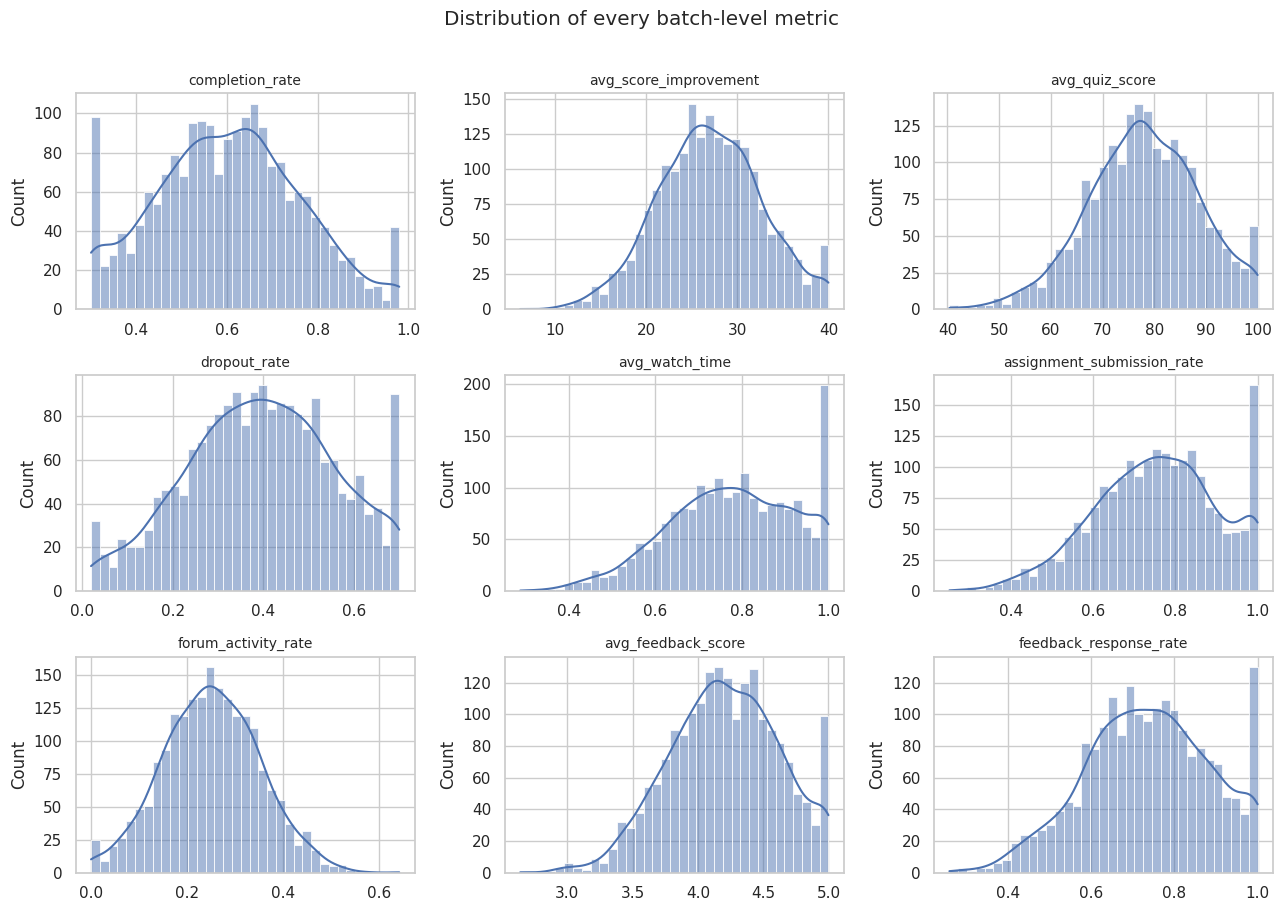

In [3]:
fig, axes = plt.subplots(3, 3, figsize=(13, 9))
for ax, c in zip(axes.ravel(), METRICS):
    sns.histplot(df[c], bins=35, kde=True, ax=ax, color="#4C72B0")
    ax.set_title(c, fontsize=10); ax.set_xlabel("")
plt.suptitle("Distribution of every batch-level metric", y=1.01); plt.tight_layout(); plt.show()

### 1.3 Anomaly check – values piled up at a limit (clipping / ceilings)

In [4]:
rows = []
for c in METRICS:
    lo, hi = df[c].min(), df[c].max()
    rows.append(dict(metric=c, min=round(lo, 3), rows_at_min=int((df[c] == lo).sum()),
                     max=round(hi, 3), rows_at_max=int((df[c] == hi).sum())))
cap = pd.DataFrame(rows).set_index("metric")
display(cap)
q1, q3 = df[METRICS].quantile(.25), df[METRICS].quantile(.75); iqr = q3 - q1
print("\nIQR-rule outliers per metric:", ((df[METRICS] < q1 - 1.5 * iqr) | (df[METRICS] > q3 + 1.5 * iqr)).sum().to_dict())

# completion and dropout should be (almost) complements
s = df.completion_rate + df.dropout_rate
print(f"\ncompletion_rate + dropout_rate: mean={s.mean():.3f}, std={s.std():.3f}, min={s.min():.2f}, max={s.max():.2f}")
print(f"corr(completion, dropout) = {df.completion_rate.corr(df.dropout_rate):.2f}")

,min,rows_at_min,max,rows_at_max
metric,,,,
completion_rate,0.300,77,0.980,32
avg_score_improvement,6.159,1,40.000,35
avg_quiz_score,40.387,1,100.000,37
dropout_rate,0.020,23,0.700,72
avg_watch_time,0.287,1,1.000,149
assignment_submission_rate,0.251,1,1.000,125
forum_activity_rate,0.000,14,0.641,1
avg_feedback_score,2.640,1,5.000,67
feedback_response_rate,0.260,1,1.000,94



IQR-rule outliers per metric: {'completion_rate': 0, 'avg_score_improvement': 6, 'avg_quiz_score': 11, 'dropout_rate': 0, 'avg_watch_time': 3, 'assignment_submission_rate': 6, 'forum_activity_rate': 5, 'avg_feedback_score': 11, 'feedback_response_rate': 5}

completion_rate + dropout_rate: mean=0.998, std=0.049, min=0.83, max=1.16
corr(completion, dropout) = -0.95


**Observations**

* Several metrics are **clipped**: `completion_rate` has a floor at 0.30 and `dropout_rate` a ceiling at 0.70 (dozens of batches sit exactly there); `avg_watch_time`, `assignment_submission_rate`, `avg_feedback_score`, `feedback_response_rate` hit their natural maximum for many batches. Clipped values are real, valid data points, so I **keep them**, but they mean the very best and very worst batches are compressed (we cannot tell a "good" batch from an "excellent" one at the ceiling).
* `completion_rate` and `dropout_rate` are **near-complements** (r ≈ −0.95, sum ≈ 1 with small noise). They are essentially one signal, so counting both would double-weight it. I use **completion only** in the score and **drop dropout** from the model inputs.
* IQR-rule outliers are few (see the printout: at most ~11 per metric, none for completion/dropout); nothing looks like a data-entry error, so no rows are removed.

### 1.4 Relationships between variables

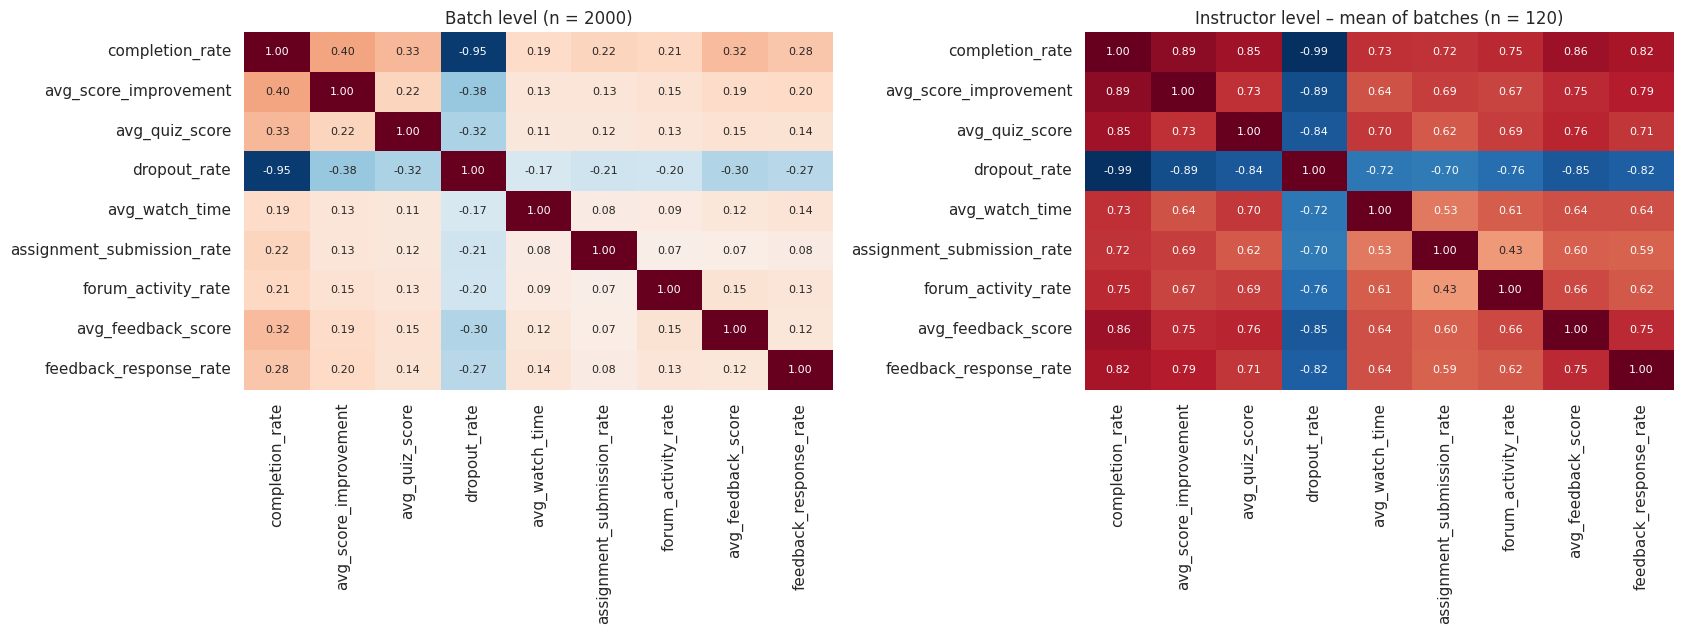

Share of instructor-level variance on the 1st principal component: 76%


In [5]:
inst_means = df.groupby("instructor_id")[METRICS].mean()
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
for ax, data, title in [(axes[0], df[METRICS], "Batch level (n = 2000)"),
                        (axes[1], inst_means, "Instructor level – mean of batches (n = 120)")]:
    sns.heatmap(data.corr(), annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax,
                cbar=False, annot_kws={"size": 8})
    ax.set_title(title)
plt.tight_layout(); plt.show()

ev = np.linalg.eigvalsh(inst_means.corr().values)[::-1] / len(METRICS)
print("Share of instructor-level variance on the 1st principal component: %.0f%%" % (100 * ev[0]))

**Observations**

* At **batch level** correlations are modest (about 0.1–0.4, apart from the completion/dropout pair): one batch is noisy (cohort mix, luck).
* At **instructor level** (averaging ~17 batches) the same metrics correlate at **mostly 0.6 – 0.99** (lowest 0.43), and a single underlying factor explains roughly three-quarters of the variance. Averaging cancels the batch noise and reveals a stable "instructor quality" signal – this is the main reason to **aggregate** and the reason a composite score is defensible.
* Such a clean one-factor structure is unusually tidy for real-world data (the dataset may be simulated), so I treat results as illustrative of the method rather than as ground truth about real instructors.

### 1.5 Who drives the variation – the instructor or the course?

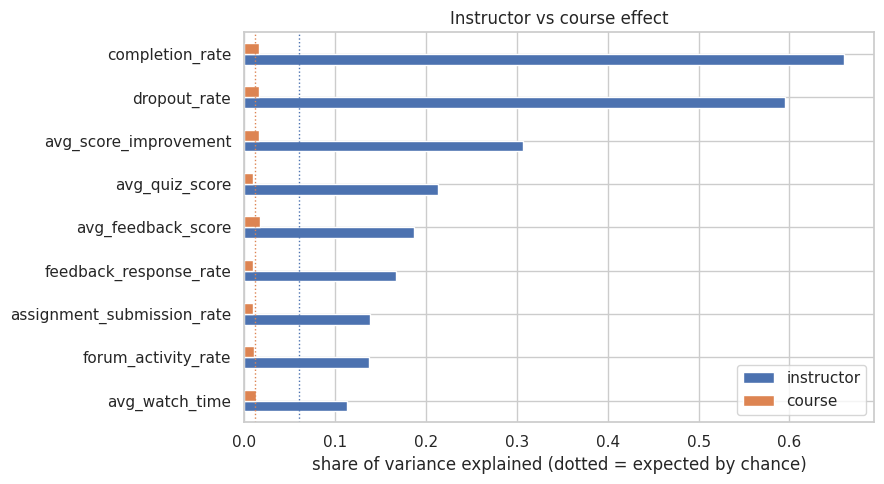

Batches per instructor: min=7, median=17, max=31 | instructors with <=10 batches: 11
Courses taught per instructor: median=12 (each instructor teaches many courses)


In [6]:
def eta_sq(frame, col, by):
    # share of total variance explained by group membership (one-way ANOVA eta^2)
    gm = frame[col].mean(); g = frame.groupby(by)[col]
    return (g.size() * (g.mean() - gm) ** 2).sum() / ((frame[col] - gm) ** 2).sum()

var_tab = pd.DataFrame({
    "instructor": {c: eta_sq(df, c, "instructor_id") for c in METRICS},
    "course":     {c: eta_sq(df, c, "course_id") for c in METRICS}})
chance_i = (df.instructor_id.nunique() - 1) / (len(df) - 1)
chance_c = (df.course_id.nunique() - 1) / (len(df) - 1)
ax = var_tab.sort_values("instructor").plot.barh(figsize=(9, 5), color=["#4C72B0", "#DD8452"])
ax.axvline(chance_i, color="#4C72B0", ls=":", lw=1); ax.axvline(chance_c, color="#DD8452", ls=":", lw=1)
ax.set_xlabel("share of variance explained (dotted = expected by chance)"); ax.set_title("Instructor vs course effect")
plt.tight_layout(); plt.show()

per_inst = df.groupby("instructor_id").size()
print("Batches per instructor: min=%d, median=%d, max=%d | instructors with <=10 batches: %d"
      % (per_inst.min(), per_inst.median(), per_inst.max(), (per_inst <= 10).sum()))
print("Courses taught per instructor: median=%d (each instructor teaches many courses)" % df.groupby("instructor_id").course_id.nunique().median())

**Observations**

* **Instructor identity** explains a large share of `completion_rate` (~66%) and `dropout_rate` (~60%) and a clearly-above-chance share of everything else. **Course** explains ~1–2% (≈ chance) of every metric.
* Therefore I do **not** adjust for course difficulty (there is no measurable course effect here), but the notebook's limitations section notes that this is something to verify on real data.
* Batches per instructor range from 7 to 31 (median 17). The few-batch instructors are the risk for noisy estimates → handled with **shrinkage** in Section 3.

## 2. Defining "Instructor Effectiveness"

**Principle:** effectiveness = *what learners achieve and how they judge the instructor*, **not** how busy they are. So the score uses **outcomes + feedback**; engagement metrics (watch time, assignments, forum) are treated as *behavioural signals that the instructor influences*, kept out of the label and used as **model inputs** instead. This also avoids circularity.

| Component | Weight | Why |
|---|---|---|
| `avg_score_improvement` | 0.30 | Closest to "value added": pre → post gain, less influenced by who enrolled |
| `completion_rate` | 0.30 | Hard outcome and the most instructor-driven metric (≈66% of variance). Dropout is its mirror image, so excluded to avoid double-counting |
| `avg_quiz_score` | 0.20 | Mastery, but partly reflects learner baseline/quiz difficulty → lower weight |
| `avg_feedback_score` | 0.20 | Learner voice, but subjective, ceilinged at 5 and affected by who responds → lower weight |

Each component is **z-scored** (so units don't matter) and combined with these weights.
**Tiers** are percentile based: **Low = bottom 25%**, **Medium = middle 50%**, **High = top 25%** of instructors. Relative tiers are appropriate because there is no absolute pass mark; the wider middle band avoids labelling the many "average" instructors as strong or weak. The cost is a mild class imbalance (25/50/25), handled in Section 5.

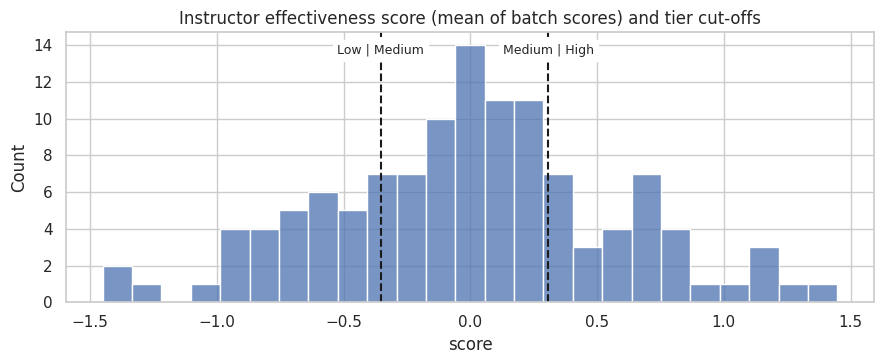

{'Low': 30, 'Medium': 60, 'High': 30}


In [7]:
W = {"completion_rate": 0.30, "avg_score_improvement": 0.30, "avg_quiz_score": 0.20, "avg_feedback_score": 0.20}
TIER_NAMES = ["Low", "Medium", "High"]

zcols = pd.DataFrame({c: (df[c] - df[c].mean()) / df[c].std() for c in METRICS})   # batch-level z-scores
df["score"] = sum(w * zcols[c] for c, w in W.items())                               # batch-level composite

def to_tier(score, cuts=None):
    # 0 = Low (<= 25th pct), 1 = Medium, 2 = High (> 75th pct)
    if cuts is None: cuts = score.quantile([0.25, 0.75]).values
    return pd.Series(np.digitize(score, cuts, right=True), index=score.index), cuts

inst_score = df.groupby("instructor_id").score.mean()
tier_full, cuts = to_tier(inst_score)
fig, ax = plt.subplots(figsize=(9, 3.8))
sns.histplot(inst_score, bins=25, ax=ax, color="#4C72B0")
for x, lab in zip(cuts, ["Low | Medium", "Medium | High"]): ax.axvline(x, color="k", ls="--"); ax.text(x, ax.get_ylim()[1]*0.92, lab, ha="center", backgroundcolor="w", fontsize=9)
ax.set_title("Instructor effectiveness score (mean of batch scores) and tier cut-offs"); plt.tight_layout(); plt.show()
print(tier_full.map(dict(enumerate(TIER_NAMES))).value_counts()[TIER_NAMES].to_dict())

### 2.1 Sensitivity – do the tiers depend on my weights?
There is "no single correct formula", so I check how much the tier assignment changes under alternative, equally reasonable definitions (agreement with my primary definition on the same 120 instructors).

In [8]:
Zc = zcols.assign(neg_dropout=-zcols["dropout_rate"])
Zi = Zc.groupby(df.instructor_id).mean()          # instructor-level mean z for every component
base = pd.Series(np.digitize(Zi[list(W)] @ pd.Series(W), (Zi[list(W)] @ pd.Series(W)).quantile([.25, .75]).values, right=True), index=Zi.index)

def tiers_from(weights):
    s = Zi[list(weights)] @ pd.Series(weights)
    return pd.Series(np.digitize(s, s.quantile([.25, .75]).values, right=True), index=Zi.index)

schemes = {
    "Primary (0.3/0.3/0.2/0.2)": W,
    "Equal weights":             {"completion_rate": .25, "avg_score_improvement": .25, "avg_quiz_score": .25, "avg_feedback_score": .25},
    "Outcomes only (no feedback)": {"completion_rate": .4, "avg_score_improvement": .4, "avg_quiz_score": .2},
    "Feedback-heavy":            {"completion_rate": .2, "avg_score_improvement": .2, "avg_quiz_score": .2, "avg_feedback_score": .4},
    "Dropout instead of completion": {"neg_dropout": .3, "avg_score_improvement": .3, "avg_quiz_score": .2, "avg_feedback_score": .2},
}
res = {k: tiers_from(w) for k, w in schemes.items()}
# data-driven alternative: first principal component of the four components
Z4 = Zi[list(W)]; vals, vecs = np.linalg.eigh(np.cov(Z4.values.T)); pc1 = vecs[:, -1] * np.sign(vecs[:, -1].sum())
s = Z4 @ pd.Series(pc1, index=Z4.columns); res["Data-driven (PC1)"] = pd.Series(np.digitize(s, s.quantile([.25, .75]).values, right=True), index=Zi.index)

sens = pd.DataFrame({k: {"same tier as primary (%)": 100 * (v == res["Primary (0.3/0.3/0.2/0.2)"]).mean(),
                         "weighted kappa": cohen_kappa_score(res["Primary (0.3/0.3/0.2/0.2)"], v, weights="quadratic"),
                         "Low<->High flips": int(((v - res["Primary (0.3/0.3/0.2/0.2)"]).abs() == 2).sum())} for k, v in res.items()}).T
sens.round(2)

,same tier as primary (%),weighted kappa,Low<->High flips
Primary (0.3/0.3/0.2/0.2),100.00,1.00,0.0
Equal weights,98.33,0.98,0.0
Outcomes only (no feedback),98.33,0.98,0.0
Feedback-heavy,95.00,0.95,0.0
Dropout instead of completion,100.00,1.00,0.0
Data-driven (PC1),98.33,0.98,0.0


**Result:** the tiers are very stable. Under five alternative definitions (equal weights, no feedback, feedback-heavy, dropout instead of completion, and a data-driven first principal component) **95–100% of instructors keep the same tier**, weighted kappa is 0.95–1.00, and **not a single instructor flips between Low and High**. The only changes are a handful of instructors sitting right on a cut-off, mostly under the feedback-heavy scheme (6 of 120 move one tier).

So the conclusions do not hinge on my exact weights. This is expected given the earlier finding that all components load on one underlying factor – but it would be less true on messier real data.

## 3. Aggregating batches → instructor level

**Handling few vs many batches – empirical-Bayes shrinkage.** A mean over 7 batches is much noisier than a mean over 30. For every metric I shrink the instructor's mean toward the overall mean:

$$\hat\mu_i = \mu + w_i(\bar y_i - \mu),\qquad w_i=\frac{\tau^2}{\tau^2+\sigma^2/n_i}$$

where $\sigma^2$ is the within-instructor (batch-to-batch) variance, $\tau^2$ the between-instructor variance and $n_i$ the number of batches. Instructors with many batches keep ≈ their own mean; instructors with few are pulled toward average, so a lucky/unlucky small sample doesn't create a false "High"/"Low".

**Aggregation functions and why**

| Feature | Function | Reason |
|---|---|---|
| each metric | **shrunk mean** | typical level, adjusted for sample size (see above) |
| outcome / feedback metrics | **standard deviation** | consistency: an instructor with the same mean but wild batch-to-batch swings is different |
| `n_batches` | **count** | experience and a confidence indicator |

`dropout_rate` is excluded from model inputs (redundant with completion). I deliberately did not use max/min (not robust to one odd batch).

**Leakage-free split.** For each instructor the batches are shuffled and divided into two halves; **A → features, B → label**. The label itself uses the same shrinkage, so a small-sample instructor is not tiered on noise.

In [9]:
MEANS = ["completion_rate", "avg_score_improvement", "avg_quiz_score", "avg_feedback_score",
         "avg_watch_time", "assignment_submission_rate", "forum_activity_rate", "feedback_response_rate"]
STD_OUT = ["completion_rate", "avg_score_improvement", "avg_quiz_score", "avg_feedback_score"]
STD_ENG = ["avg_watch_time", "assignment_submission_rate", "forum_activity_rate"]

def eb_shrink(frame, col, group="instructor_id"):
    # empirical-Bayes shrinkage of per-instructor means toward the grand mean
    g = frame.groupby(group)[col]
    n, m, mu = g.size(), g.mean(), frame[col].mean()
    sw2 = ((frame[col] - g.transform("mean")) ** 2).sum() / (len(frame) - len(n))   # within-instructor variance
    tau2 = max(m.var(ddof=1) - (sw2 / n).mean(), 1e-9)                                # between-instructor variance
    w = tau2 / (tau2 + sw2 / n)
    return mu + w * (m - mu)

def split_halves(frame, seed):
    # random 50/50 split of each instructor's batches; which half gets the odd batch is randomised
    rng = np.random.default_rng(seed)
    f = frame.sample(frac=1, random_state=seed)
    pos = f.groupby("instructor_id").cumcount()
    flip = pd.Series(rng.integers(0, 2, f.instructor_id.nunique()), index=sorted(f.instructor_id.unique()))
    f["half"] = (pos + f.instructor_id.map(flip)) % 2
    return f[f.half == 0], f[f.half == 1]            # (feature half A, label half B)

def build_dataset(frame, seed):
    A, B = split_halves(frame, seed)
    X = pd.DataFrame({f"{c}_mean": eb_shrink(A, c) for c in MEANS})
    for c in STD_OUT + STD_ENG: X[f"{c}_std"] = A.groupby("instructor_id")[c].std()
    X["n_batches"] = A.groupby("instructor_id").size()
    score = eb_shrink(B, "score")                     # label = shrunk composite on the OTHER batches
    y, cuts = to_tier(score)
    return X, y, score, pd.Series(frame.groupby("instructor_id").size()).loc[X.index]

FULL = [f"{c}_mean" for c in MEANS] + [f"{c}_std" for c in STD_OUT] + ["n_batches"]
LEAD = [f"{c}_mean" for c in ["avg_watch_time", "assignment_submission_rate", "forum_activity_rate", "feedback_response_rate"]] \
       + [f"{c}_std" for c in STD_ENG] + ["n_batches"]

X_all, y, label_score, n_total = build_dataset(df, SEED)
print("Instructors:", len(X_all), "| features FULL:", len(FULL), "| LEAD:", len(LEAD))
print("Tier counts:", y.map(dict(enumerate(TIER_NAMES))).value_counts()[TIER_NAMES].to_dict())
X_all[FULL].head()

Instructors: 120 | features FULL: 13 | LEAD: 8
Tier counts: {'Low': 30, 'Medium': 60, 'High': 30}


,completion_rate_mean,avg_score_improvement_mean,avg_quiz_score_mean,avg_feedback_score_mean,avg_watch_time_mean,assignment_submission_rate_mean,forum_activity_rate_mean,feedback_response_rate_mean,completion_rate_std,avg_score_improvement_std,avg_quiz_score_std,avg_feedback_score_std,n_batches
instructor_id,,,,,,,,,,,,,
I_001,0.530159,26.359833,78.511948,4.303287,0.763325,0.715730,0.244534,0.680167,0.088772,6.139455,8.994158,0.311006,13
I_002,0.768048,30.365290,83.541043,4.196785,0.790379,0.784873,0.275115,0.791330,0.113161,3.763483,12.062556,0.509475,10
I_003,0.798658,27.812127,80.260754,4.327426,0.786122,0.760121,0.277624,0.805750,0.092178,5.925505,10.438743,0.292284,9
I_004,0.459214,23.962295,75.849554,4.051525,0.779984,0.781897,0.214735,0.699689,0.064329,4.568806,10.854813,0.443227,9
I_005,0.881195,31.135495,81.736101,4.259536,0.795816,0.813562,0.314011,0.779011,0.066418,5.367582,7.617120,0.314567,10


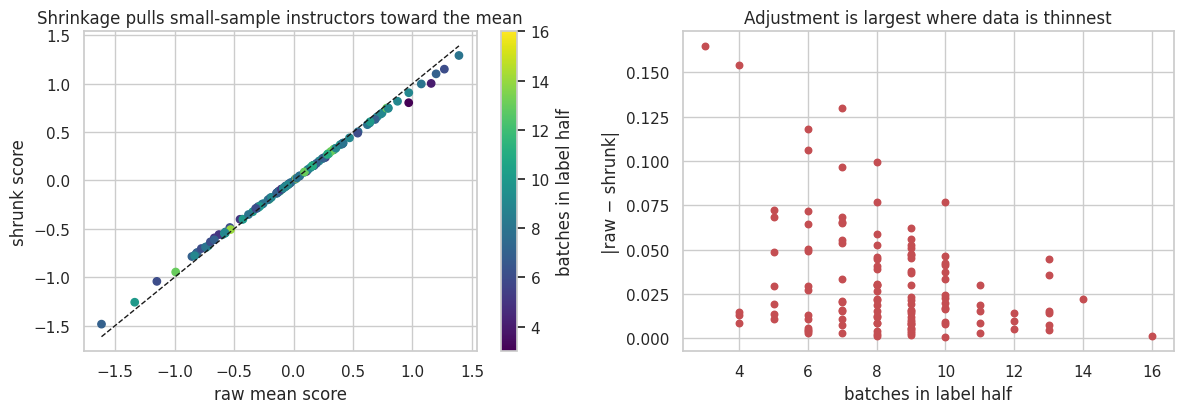

Highest variance-inflation factors among FULL features:
completion_rate_mean           8.4
avg_score_improvement_mean     4.5
avg_quiz_score_mean            3.3
avg_feedback_score_mean        2.7
feedback_response_rate_mean    2.6
forum_activity_rate_mean       2.0


In [10]:
# Effect of shrinkage: raw vs shrunk label score, coloured by number of batches in the label half
_, B = split_halves(df, SEED)
raw = B.groupby("instructor_id").score.mean(); shr = eb_shrink(B, "score"); nB = B.groupby("instructor_id").size()
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
sc = ax[0].scatter(raw, shr, c=nB, cmap="viridis", s=28); plt.colorbar(sc, ax=ax[0], label="batches in label half")
lim = [min(raw.min(), shr.min()), max(raw.max(), shr.max())]; ax[0].plot(lim, lim, "k--", lw=1)
ax[0].set_xlabel("raw mean score"); ax[0].set_ylabel("shrunk score"); ax[0].set_title("Shrinkage pulls small-sample instructors toward the mean")
ax[1].scatter(nB, (raw - shr).abs(), s=22, color="#C44E52"); ax[1].set_xlabel("batches in label half"); ax[1].set_ylabel("|raw − shrunk|")
ax[1].set_title("Adjustment is largest where data is thinnest"); plt.tight_layout(); plt.show()

# multicollinearity check on the model inputs
def vif(frame):
    out = {}
    for c in frame.columns:
        r2 = LinearRegression().fit(frame.drop(columns=c), frame[c]).score(frame.drop(columns=c), frame[c]); out[c] = 1 / (1 - r2)
    return pd.Series(out).sort_values(ascending=False)
print("Highest variance-inflation factors among FULL features:"); print(vif(X_all[FULL]).head(6).round(1).to_string())

**Observations**

* Shrinkage moves instructors with few batches the most (right panel) and leaves instructors with many batches almost untouched – which is exactly the intended behaviour.
* Variance-inflation factors are moderate (highest ≈ 8 for `completion_rate_mean`, others ≤ 4.5): features overlap, but not catastrophically. That is why I use a **regularised** model and report **grouped** importance in Section 6.
* The consistency features (std) and `n_batches` are included on purpose so the model can *tell me* whether they matter; Section 6 shows they add almost nothing here.

## 4. Building the model

* **Preprocessing:** standard scaling, **fitted inside each cross-validation fold** (a pipeline) so test data never influences it.
* **Validation:** only 120 instructors, so a single train/test split would be very noisy. I use **repeated stratified 5-fold cross-validation** (5 repeats). Each row is one instructor, so no instructor appears in both train and test.
* **Imbalance:** 25/50/25 → `class_weight="balanced"`.
* **Models:** a dummy baseline, **regularised logistic regression** (interpretable; C chosen by an inner CV, i.e. nested), random forest, gradient boosting.
* **Two input sets:**
  * **FULL** – all aggregated features from half A (history of outcomes, feedback, engagement, consistency, experience).
  * **LEAD** – *only engagement + feedback-response behaviour* (no outcomes, no ratings): "can we flag who is likely effective from cheap, early behavioural signals?"

In [11]:
qwk = make_scorer(cohen_kappa_score, weights="quadratic")
SCORING = {"macro_F1": "f1_macro", "balanced_acc": "balanced_accuracy", "QWK": qwk}

def models():
    return {
        "Baseline (stratified guess)": DummyClassifier(strategy="stratified", random_state=SEED),
        "Logistic regression": make_pipeline(StandardScaler(), LogisticRegressionCV(Cs=np.logspace(-2, 1, 8), cv=3, scoring="f1_macro",
                                                              class_weight="balanced", max_iter=3000)),
        "Random forest": make_pipeline(StandardScaler(), RandomForestClassifier(300, min_samples_leaf=3, class_weight="balanced_subsample",
                                                              random_state=SEED, n_jobs=-1)),
        "Gradient boosting": make_pipeline(StandardScaler(), GradientBoostingClassifier(n_estimators=120, max_depth=2, learning_rate=0.05,
                                                              subsample=0.8, random_state=SEED)),
    }

def cv_eval(model, X, y, repeats=5):
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=repeats, random_state=SEED)
    r = cross_validate(model, X, y, cv=cv, scoring=SCORING)
    return {k.replace("test_", ""): (r[k].mean(), r[k].std()) for k in r if k.startswith("test_")}

rows = []
for fs_name, cols in [("FULL", FULL), ("LEAD (engagement only)", LEAD)]:
    for name, m in models().items():
        r = cv_eval(m, X_all[cols], y)
        rows.append({"features": fs_name, "model": name, **{f"{k}": f"{v[0]:.3f} ± {v[1]:.3f}" for k, v in r.items()}})
results = pd.DataFrame(rows).set_index(["features", "model"]); results

macro_F1  \
features               model                                        
FULL                   Baseline (stratified guess)  0.362 ± 0.082   
                       Logistic regression          0.785 ± 0.062   
                       Random forest                0.842 ± 0.042   
                       Gradient boosting            0.807 ± 0.064   
LEAD (engagement only) Baseline (stratified guess)  0.362 ± 0.082   
                       Logistic regression          0.672 ± 0.073   
                       Random forest                0.622 ± 0.105   
                       Gradient boosting            0.593 ± 0.096   

                                                     balanced_acc  \
features               model                                        
FULL                   Baseline (stratified guess)  0.366 ± 0.076   
                       Logistic regression          0.806 ± 0.040   
                       Random forest                0.838 ± 0.046   
                       Gradient boosting            0.806 ± 0.058   
LEAD (engagement only) Baseline (stratified guess)  0.366 ± 0.076   
                       Logistic regression          0.709 ± 0.071   
                       Random forest                0.624 ± 0.105   
                       Gradient boosting            0.592 ± 0.094   

                                                              QWK  
features               model                                       
FULL                   Baseline (stratified guess)  0.062 ± 0.149  
                       Logistic regression          0.801 ± 0.044  
                       Random forest                0.842 ± 0.043  
                       Gradient boosting            0.810 ± 0.059  
LEAD (engagement only) Baseline (stratified guess)  0.062 ± 0.149  
                       Logistic regression          0.704 ± 0.063  
                       Random forest                0.616 ± 0.125  
                       Gradient boosting            0.579 ± 0.115

**Reading the table** (mean ± sd over 25 folds; the baseline is a random guess that respects class sizes)

* **FULL features:** every real model is about **2× the baseline** (macro-F1 ≈ 0.79–0.84 vs 0.36). Random forest is highest (0.84), gradient boosting 0.81, logistic regression 0.79. The gaps between the three are about one fold-to-fold standard deviation, i.e. not clearly meaningful with only 120 instructors.
* **LEAD (engagement-only) features:** macro-F1 ≈ 0.60–0.67, clearly above the baseline but well below FULL. Here **logistic regression is best** and the tree models do worse – with noisy, weak inputs and few samples, the flexible models overfit.
* **Choice:** I carry **logistic regression** forward as the primary model because it is competitive, gives directions of effect that can be explained to non-technical readers, and is the most stable across both feature sets. I note honestly that the random forest scored somewhat higher on FULL.

## 5. Evaluating the model

**Metric choices**

* **Macro-F1** – averages F1 across the three tiers equally, so the smaller Low/High tiers matter as much as the big Medium tier (plain accuracy would reward predicting "Medium" for everyone ≈ 50%).
* **Balanced accuracy** – mean recall per tier; same reason.
* **Quadratic-weighted kappa (QWK)** – tiers are *ordered*; calling a Low instructor "High" is worse than "Medium". QWK penalises far-off errors more.
* **Per-tier precision/recall + confusion matrix** – to see *which* mistakes are made.

I use **logistic regression on the FULL feature set** as the primary model. The Section 4 table shows the random forest scoring somewhat higher on FULL, but the gap is about one fold-to-fold standard deviation, logistic regression does best on the engagement-only set, and its coefficients give a direction of effect that is easy to explain. With 120 instructors I prefer the simpler, more explainable model; the random forest is the natural next step if raw accuracy mattered more.

              precision    recall  f1-score   support

         Low      0.767     0.767     0.767        30
      Medium      0.833     0.750     0.789        60
        High      0.778     0.933     0.848        30

    accuracy                          0.800       120
   macro avg      0.793     0.817     0.802       120
weighted avg      0.803     0.800     0.799       120

QWK = 0.810 | Low<->High confusions: 0 of 120


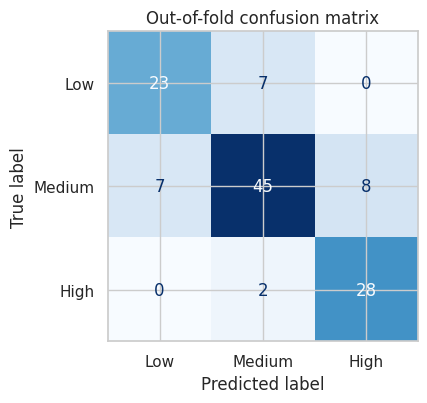

In [12]:
primary = models()["Logistic regression"]
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
P = cross_val_predict(primary, X_all[FULL], y, cv=skf, method="predict_proba")      # out-of-fold probabilities
pred = pd.Series(P.argmax(1), index=y.index)

print(classification_report(y, pred, target_names=TIER_NAMES, digits=3))
print("QWK = %.3f | Low<->High confusions: %d of %d" % (cohen_kappa_score(y, pred, weights="quadratic"), int(((y - pred).abs() == 2).sum()), len(y)))
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ConfusionMatrixDisplay(confusion_matrix(y, pred), display_labels=TIER_NAMES).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Out-of-fold confusion matrix"); plt.tight_layout(); plt.show()

**Results (out-of-fold, 120 instructors)**

* Accuracy 0.80, **macro-F1 0.80**, **QWK 0.81**. All 24 mistakes are **neighbouring-tier** mistakes – **0 Low↔High confusions**.
* **Low:** precision 0.77 / recall 0.77. **Medium:** precision 0.83 / recall 0.75. **High:** precision 0.78 / recall **0.93**.
* **Class imbalance (25/50/25):** because Medium is twice as large, a plain-accuracy model could get ≈ 50% by always answering "Medium". Balanced class weights fix this, but with a trade-off: borderline Medium instructors are pushed toward the extremes (Medium has the lowest recall, High the highest recall but lower precision). That is a reasonable bias when the extreme tiers are the ones the business cares about.
* **Baseline for context:** a stratified random guess scores macro-F1 0.36 (Section 4).

**Robustness:** repeating everything over **20 different random half-splits** gives macro-F1 **0.78 ± 0.03** (worst split 0.70) for FULL and **0.64 ± 0.03** for LEAD, so the result is not an artefact of one lucky split.

**Precision vs recall (5.1):**
* For a **Low** (coaching) alert, a threshold of about **0.4** gives recall ≈ 0.80 with precision ≈ 0.63 (flagging 38 instructors to catch 24 of the 30 truly Low). Raising it to 0.7 gives precision 0.84 but recall only 0.70.
* For a **High** (recognition) label, a threshold of **0.6** raises precision to 0.85 while recall stays at 0.93, so it costs almost nothing – a good choice when wrongly crowning someone is the worse error.

### 5.1 Precision vs recall – a threshold trade-off
The tier is chosen by `argmax` of the predicted probabilities. In a product, the *cost* of mistakes differs per tier, so the decision threshold can be moved:
* **Low tier** (e.g. trigger coaching/support): **recall** matters – missing a struggling instructor is costly; a false alarm only costs a coaching conversation.
* **High tier** (e.g. recognition, featuring, rewards): **precision** matters – wrongly crowning someone is costly.

In [13]:
rows = []
for k, name in [(0, "Low"), (2, "High")]:
    for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
        flag = P[:, k] >= t; true = (y.values == k)
        rows.append(dict(tier=name, threshold=t, flagged=int(flag.sum()), precision=(true & flag).sum() / max(flag.sum(), 1), recall=(true & flag).sum() / true.sum()))
pd.DataFrame(rows).round(2).pivot(index="threshold", columns="tier", values=["flagged", "precision", "recall"])

flagged       precision       recall      
tier         High   Low      High   Low   High   Low
threshold                                           
0.3          44.0  48.0      0.66  0.56   0.97  0.90
0.4          39.0  38.0      0.72  0.63   0.93  0.80
0.5          35.0  30.0      0.80  0.77   0.93  0.77
0.6          33.0  28.0      0.85  0.79   0.93  0.73
0.7          25.0  25.0      0.88  0.84   0.73  0.70

### 5.2 Robustness – does the result depend on the random half-split?

In [14]:
def run_seed(seed, cols):
    X, yy, _, _ = build_dataset(df, seed)
    r = cv_eval(models()["Logistic regression"], X[cols], yy, repeats=2)
    return r["macro_F1"][0], r["QWK"][0]

rob = {}
for name, cols in [("FULL", FULL), ("LEAD", LEAD)]:
    out = np.array([run_seed(s, cols) for s in range(20)])
    rob[name] = {"macro-F1 mean": out[:, 0].mean(), "macro-F1 sd": out[:, 0].std(), "macro-F1 min": out[:, 0].min(), "QWK mean": out[:, 1].mean()}
pd.DataFrame(rob).T.round(3)

,macro-F1 mean,macro-F1 sd,macro-F1 min,QWK mean
FULL,0.778,0.032,0.697,0.789
LEAD,0.636,0.033,0.568,0.654


### 5.3 Why the split matters – the circular ("leaky") version
Here the label and the features come from **the same batches**. The model is just reconstructing the formula.

In [15]:
X_leak = pd.DataFrame({f"{c}_mean": eb_shrink(df, c) for c in MEANS})
y_leak, _ = to_tier(eb_shrink(df, "score"))
r = cv_eval(models()["Logistic regression"], X_leak, y_leak)
cmp = pd.DataFrame({"Leaky (same batches)": {k: v[0] for k, v in r.items()},
                    "Leakage-free (primary)": {k: cv_eval(models()["Logistic regression"], X_all[FULL], y)[k][0] for k in r}}).round(3)
cmp

,Leaky (same batches),Leakage-free (primary)
macro_F1,0.946,0.785
balanced_acc,0.948,0.806
QWK,0.946,0.801


**The circular version reports macro-F1 ≈ 0.95; the honest, leakage-free version reports ≈ 0.79.** The extra ~0.16 is not skill – it is the model re-learning my own formula from the same numbers. This is why I would distrust any "95% accurate instructor-effectiveness model" that doesn't explain how its label was separated from its inputs. The 0.79 is the number to trust.

### 5.4 Where does the model go wrong?

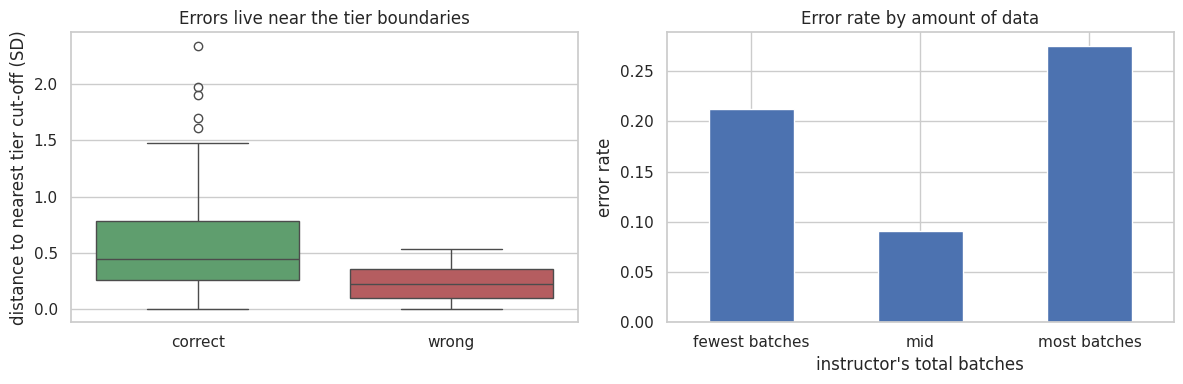

Median distance to cut-off: correct = 0.45 SD, wrong = 0.22 SD
{'fewest batches': 0.213, 'mid': 0.091, 'most batches': 0.275}


In [16]:
dist = pd.Series(np.minimum(abs(label_score - label_score.quantile(.25)), abs(label_score - label_score.quantile(.75))), index=y.index)
dist = dist / label_score.std()
wrong = (pred != y)
bucket = pd.qcut(n_total, 3, labels=["fewest batches", "mid", "most batches"])
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(x=wrong.map({False: "correct", True: "wrong"}), y=dist, ax=ax[0], palette=["#55A868", "#C44E52"])
ax[0].set_ylabel("distance to nearest tier cut-off (SD)"); ax[0].set_xlabel(""); ax[0].set_title("Errors live near the tier boundaries")
er = wrong.groupby(bucket).mean(); er.plot.bar(ax=ax[1], color="#4C72B0", rot=0); ax[1].set_ylabel("error rate"); ax[1].set_xlabel("instructor's total batches"); ax[1].set_title("Error rate by amount of data")
plt.tight_layout(); plt.show()
print("Median distance to cut-off: correct = %.2f SD, wrong = %.2f SD" % (dist[~wrong].median(), dist[wrong].median()))
print(er.round(3).to_dict())

**Observations**

* **Errors sit on the boundaries.** The median wrongly-classified instructor is only ~0.22 SD from a tier cut-off, versus ~0.45 SD for correct ones. Percentile tiers draw hard lines through a continuous score, so instructors just either side of a line are inherently hard to separate – even the label itself is noisy at that distance. This is a property of tiering, not just of the model.
* **Few batches vs many:** the error rate by amount of data is 0.21 (fewest batches), 0.09 (middle), 0.28 (most batches). That is **not monotonic**, and with ~40 instructors per group each estimate has a standard error of roughly ±0.05–0.07, so I do not read anything into it. There is no evidence that few-batch instructors are classified worse (shrinkage seems to be doing its job), but 11 instructors with ≤ 10 batches is too few to prove it.

## 6. Interpreting the results

Features are strongly correlated (see the VIFs), so single-feature importances **split credit** among similar features and can understate a signal. I therefore report importance at two levels: **individual features** and **feature groups** (permuted together). Importance = drop in macro-F1 on held-out folds when the feature(s) are shuffled (higher = the model relies on it more).

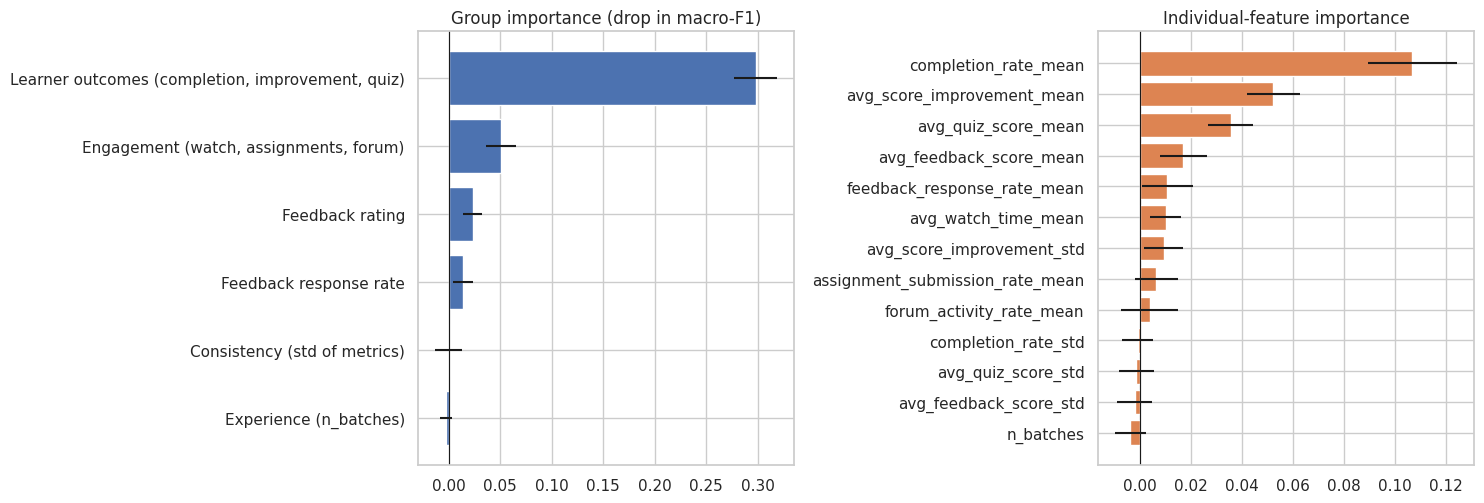

GROUP importance (drop in macro-F1, mean ± s.e.)
                                                   drop     se
Learner outcomes (completion, improvement, quiz)  0.298  0.021
Engagement (watch, assignments, forum)            0.051  0.014
Feedback rating                                   0.023  0.009
Feedback response rate                            0.014  0.010
Consistency (std of metrics)                      0.000  0.013
Experience (n_batches)                           -0.003  0.006

TOP-6 individual features
                              drop     se
completion_rate_mean         0.107  0.017
avg_score_improvement_mean   0.052  0.010
avg_quiz_score_mean          0.036  0.009
avg_feedback_score_mean      0.017  0.009
feedback_response_rate_mean  0.011  0.010
avg_watch_time_mean          0.010  0.006


In [17]:
GROUPS = {
    "Learner outcomes (completion, improvement, quiz)": ["completion_rate_mean", "avg_score_improvement_mean", "avg_quiz_score_mean"],
    "Feedback rating":            ["avg_feedback_score_mean"],
    "Feedback response rate":     ["feedback_response_rate_mean"],
    "Engagement (watch, assignments, forum)": ["avg_watch_time_mean", "assignment_submission_rate_mean", "forum_activity_rate_mean"],
    "Consistency (std of metrics)": [c for c in FULL if c.endswith("_std")],
    "Experience (n_batches)":     ["n_batches"],
}

def perm_importance(groups, repeats_cv=3, n_perm=20):
    rng = np.random.default_rng(SEED); out = {g: [] for g in groups}
    cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=repeats_cv, random_state=SEED)
    for tr, te in cv.split(X_all[FULL], y):
        m = models()["Logistic regression"].fit(X_all[FULL].iloc[tr], y.iloc[tr])
        Xte, yte = X_all[FULL].iloc[te], y.iloc[te]; base = f1_score(yte, m.predict(Xte), average="macro")
        for g, cols in groups.items():
            drops = []
            for _ in range(n_perm):
                Xp = Xte.copy(); Xp[cols] = Xte[cols].values[rng.permutation(len(Xte))]
                drops.append(base - f1_score(yte, m.predict(Xp), average="macro"))
            out[g].append(np.mean(drops))
    return pd.DataFrame({g: [np.mean(v), np.std(v) / np.sqrt(len(v))] for g, v in out.items()}, index=["drop", "se"]).T.sort_values("drop")

grp = perm_importance(GROUPS)
ind = perm_importance({c: [c] for c in FULL})
fig, ax = plt.subplots(1, 2, figsize=(15, 5.2))
ax[0].barh(grp.index, grp["drop"], xerr=grp["se"], color="#4C72B0"); ax[0].set_title("Group importance (drop in macro-F1)")
ax[1].barh(ind.index, ind["drop"], xerr=ind["se"], color="#DD8452"); ax[1].set_title("Individual-feature importance")
for a in ax: a.axvline(0, color="k", lw=.8)
plt.tight_layout(); plt.show()
print("GROUP importance (drop in macro-F1, mean ± s.e.)"); print(grp.sort_values("drop", ascending=False).round(3).to_string())
print("\nTOP-6 individual features"); print(ind.sort_values("drop", ascending=False).head(6).round(3).to_string())

Chosen regularisation C = 3.728


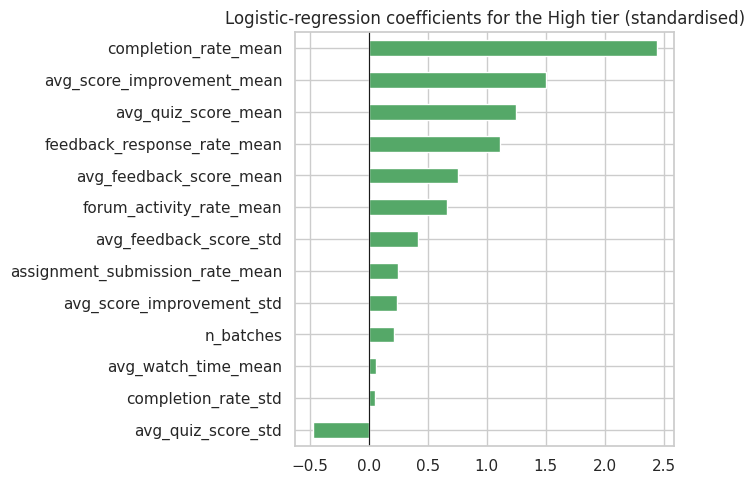

                                  Low  Medium  High
completion_rate_mean            -2.36   -0.08  2.44
avg_score_improvement_mean      -1.57    0.07  1.50
avg_quiz_score_mean             -0.36   -0.88  1.24
avg_feedback_score_mean         -0.76    0.01  0.75
avg_watch_time_mean              0.09   -0.15  0.06
assignment_submission_rate_mean -0.32    0.08  0.24
forum_activity_rate_mean        -0.68    0.01  0.66
feedback_response_rate_mean     -0.53   -0.58  1.11
completion_rate_std              0.03   -0.08  0.05
avg_score_improvement_std       -0.41    0.17  0.24
avg_quiz_score_std               0.21    0.26 -0.48
avg_feedback_score_std          -0.15   -0.26  0.42
n_batches                       -0.01   -0.20  0.21


In [18]:
# Direction of effects: standardised logistic-regression coefficients (fit on all instructors; class "High" vs the rest)
final = models()["Logistic regression"].fit(X_all[FULL], y)
coef = pd.DataFrame(final[-1].coef_, columns=FULL, index=TIER_NAMES).T
print("Chosen regularisation C = %.3f" % final[-1].C_[0])
coef["High"].sort_values().plot.barh(figsize=(7, 5), color="#55A868"); plt.axvline(0, color="k", lw=.8)
plt.title("Logistic-regression coefficients for the High tier (standardised)"); plt.tight_layout(); plt.show()
print(coef.round(2).to_string())

### Findings

**By group (drop in macro-F1 when shuffled):** learner outcomes **0.30** (dominant) ≫ engagement **0.05** > feedback rating **0.02** > feedback response rate **0.01** > consistency ≈ **0.00** ≈ experience (`n_batches`) ≈ **0.00**.

**Top individual features:** `completion_rate_mean` (0.107), `avg_score_improvement_mean` (0.052), `avg_quiz_score_mean` (0.036), `avg_feedback_score_mean` (0.017).

**Direction (coefficients):** higher completion (+2.4) and score improvement (+1.5) push strongly toward **High** and, symmetrically, away from **Low** (−2.4, −1.6). The Medium tier has coefficients near 0 – it is simply "not clearly high or low". Quiz, feedback and forum activity point the same way but more weakly. The consistency and experience features have small, noisy coefficients.

**Caveat on importance:** the model's top features are the same kinds of measures that define the label (just from different batches), so this mostly tells us that *outcome performance persists across an instructor's batches* – which is a useful result in itself (it says the instructor matters), but not proof that those features *cause* effectiveness. Features are correlated, so individual importances are shared among them; the group view is the safer reading.

### 6.1 What a product could show – an instructor scorecard (out-of-fold, so nobody is scored by a model that saw them)

In [19]:
card = pd.DataFrame({"predicted_tier": pred.map(dict(enumerate(TIER_NAMES))), "confidence": P.max(1).round(2),
                     "actual_tier": y.map(dict(enumerate(TIER_NAMES))), "total_batches": n_total})
card["needs_human_review"] = (card.confidence < 0.55) | (card.total_batches <= 10)
print("Flagged for human review (low confidence or <=10 batches): %d of %d" % (card.needs_human_review.sum(), len(card)))
print("Accuracy on confident, well-evidenced instructors: %.2f  vs  flagged: %.2f" % (
      (card.predicted_tier == card.actual_tier)[~card.needs_human_review].mean(),
      (card.predicted_tier == card.actual_tier)[card.needs_human_review].mean()))
ok = (card.predicted_tier == card.actual_tier)
print("\nAccuracy by confidence tercile:", ok.groupby(pd.qcut(card.confidence, 3, labels=["low", "mid", "high"])).mean().round(2).to_dict())
print("Accuracy for instructors with <=10 batches (n=%d): %.2f | with >10: %.2f" % ((card.total_batches <= 10).sum(), ok[card.total_batches <= 10].mean(), ok[card.total_batches > 10].mean()))
card.sort_values("confidence").head(8)

Flagged for human review (low confidence or <=10 batches): 25 of 120
Accuracy on confident, well-evidenced instructors: 0.80  vs  flagged: 0.80

Accuracy by confidence tercile: {'low': 0.72, 'mid': 0.75, 'high': 0.92}
Accuracy for instructors with <=10 batches (n=11): 0.82 | with >10: 0.80


,predicted_tier,confidence,actual_tier,total_batches,needs_human_review
instructor_id,,,,,
I_111,Medium,0.46,Medium,22,True
I_017,High,0.47,Medium,24,True
I_092,Medium,0.47,Medium,26,True
I_108,Medium,0.47,Medium,21,True
I_046,Medium,0.49,Medium,12,True
I_062,Medium,0.51,Medium,31,True
I_054,Medium,0.51,Medium,19,True
I_001,Medium,0.51,Medium,25,True


**Observations on the scorecard**

* The review flag as I defined it (confidence < 0.55 or ≤ 10 batches; 25 instructors) did **not** isolate the errors: accuracy is 0.80 for flagged and 0.80 for unflagged. Instructors with ≤ 10 batches are also not less accurate (0.82, but only n = 11).
* Confidence is nonetheless informative at the top end: accuracy by confidence tercile is **0.72 / 0.75 / 0.92** (low / mid / high). So a sensible rule is to *trust the high-confidence third* and route the rest to human review – but the exact cut-off should be tuned on more data, and I don't claim the current 0.55 rule is validated.

**How an EdTech product could use this (as decision support, not a verdict)**

1. **Early-warning for batches** – the engagement-only (LEAD) model reaches macro-F1 ≈ 0.64–0.67 (vs 0.36 baseline) *before* outcomes are in, so it can flag a batch/instructor pairing that is drifting toward Low while there is still time to intervene.
2. **Coaching triggers** – use a recall-oriented threshold (~0.4) for Low, so struggling instructors are rarely missed; a false alarm only costs a conversation.
3. **Recognition / featuring** – use a precision-oriented threshold (~0.6) for High.
4. **Batch allocation** – help balance who teaches the hardest / most important cohorts, with a human in the loop.
5. **Always show confidence and the evidence (number of batches)**, and let instructors see and contest their own data.

## 7. Mandatory analysis questions

### Q1. Which features most influenced instructor effectiveness, and why?

* **Learner outcomes dominate** (group importance 0.30 vs ≤ 0.05 for everything else). Within them, **completion rate** is first (0.11), then **score improvement** (0.05) and **quiz score** (0.04).
* **Why:** completion is the most instructor-driven metric in the data (instructor identity explains ≈ 66% of its variance, course only ≈ 1–2%), it is stable from batch to batch, and it also carries weight in the label. Improvement and quiz are persistent in the same way.
* **Engagement** (watch time, assignments, forum) matters modestly (0.05); **feedback rating** and **feedback response rate** a little (0.02, 0.01). **Consistency** (std) and **experience** (`n_batches`) added essentially nothing.
* **Caveat:** outcome features overlap conceptually with the label (same metrics, different batches), so the result largely says *"good outcomes persist across an instructor's batches"*. That is informative about the instructor effect, but it is not a causal claim.

### Q2. Which variables could be misleading or confounded?

* **Completion / dropout:** driven partly by learner motivation, cost (free vs paid), schedule and course difficulty, not only by teaching. Also near-duplicates of each other (r = −0.95) and clipped at 0.30 / 0.70.
* **Quiz score:** depends on how hard the quizzes are and on learners' starting level; ceiling at 100 (37 batches).
* **Score improvement:** no pre-score is given, and learners who start low can gain more (regression to the mean); capped at 40 (35 batches). An instructor teaching beginners can look "better" than one teaching advanced learners.
* **Feedback score:** only a fraction of learners respond (26–100%), unhappy or very happy learners respond more, ratings can be influenced by easy grading, and the scale is capped at 5 (67 batches). **Feedback response rate** is ambiguous – high may mean engaged learners, not a better teacher.
* **Engagement metrics:** direction is ambiguous – heavy forum activity can mean vibrant discussion or confusion; high watch time can mean engagement or re-watching a confusing lesson. All are normalised/capped (149 batches at maximum watch time).
* **Unobserved confounders – the biggest issue:** which learners an instructor gets (cohort quality, batch size, time of year, course level). If strong instructors are assigned to stronger or more motivated cohorts, "instructor effect" and "learner effect" cannot be separated with this data. In this dataset the course explains only ≈ 1–2% of variance, but the same may not hold on real data.
* **`n_batches`:** may reflect survivorship (weak instructors given fewer batches) rather than experience.

### Q3. How could this model fail in real-world usage?

* **Relative labels:** tiers are percentiles, so exactly ~25% are always "Low" – even if every instructor is good. The label says nothing about absolute quality.
* **Boundary errors:** ~1 in 5 instructors is mis-tiered (all by one tier in my test), concentrated near cut-offs; a person just below a line is treated very differently from one just above it.
* **Gaming (Goodhart's law):** if instructors know the metrics, they can make quizzes easier, ease completion requirements, or solicit ratings only from happy learners.
* **Feedback loops:** a "Low" instructor may get weaker cohorts or fewer batches, which then lowers their metrics further.
* **Distribution shift:** new courses, formats or learner populations; the model assumes instructors behave consistently across batches.
* **Unfairness:** instructors who teach harder courses or disadvantaged learners can be penalised for factors they do not control.
* **Small samples and clipping:** new instructors with few batches have noisy scores; clipped values hide the very best/worst batches.
* **Over-trust:** the dataset is unusually clean (one factor explains ≈ 76% of instructor-level variance), so real data is likely to give lower accuracy than reported here.

### Q4. What additional data would improve the analysis?

* **Learner baselines:** pre-assessment scores, prior experience, demographics-lite – to measure *value added* and adjust for who enrols.
* **Batch context:** enrolment size, start date/season, schedule, delivery mode, course level/difficulty, instructor workload.
* **Time stamps** to allow a *true forward-looking* test (train on earlier batches, predict later ones), measure improvement over time and detect trends.
* **Learner-level records** (not just batch averages) so we can model value-added properly and know the denominators behind each rate.
* **Richer feedback:** number of responses, text comments, per-question ratings, complaints and refunds.
* **Assessment details:** quiz difficulty/blueprint and whether assessments are shared across batches.
* **Longer-term outcomes:** retention, re-enrolment, certification, job placement.
* **Instructor attributes:** tenure, training, language, support/TA hours.
* **Assignment process:** knowing how instructors are allocated to batches (or any randomisation) would greatly help separating instructor from cohort effects.

### Q5. Should this model be used for instructor performance evaluation? Why or why not?

**Not as the basis for high-stakes decisions (pay, promotion, termination). Yes, cautiously, as decision support.**

* **Against high-stakes use:** it predicts a score *I defined*, not an objective truth about teaching quality; it cannot separate the instructor from the learners and course; ~20% of instructors are mis-tiered; tiers are relative by construction; metrics can be gamed; and it may penalise instructors for factors outside their control.
* **For low-stakes use:** early-warning, coaching, support allocation and spotting positive examples to learn from, **provided** that (1) a human reviews every flag, (2) confidence and number of batches are shown, (3) instructors can see and contest their data, (4) results are checked for unfair patterns across courses and cohorts, and (5) the model is validated on real, time-ordered data before any use.

## Limitations & honest notes

* Only **120 instructors**, so every metric has real uncertainty (sd ≈ 0.03 across splits, ≈ 0.04–0.06 across folds); small differences between models (e.g. random forest 0.84 vs logistic regression 0.79) should not be over-interpreted.
* The data looks **simulated** (very clean single-factor structure), so absolute numbers are likely optimistic for real platforms.
* **The label is my definition.** Sensitivity checks (Section 2.1) show tiers are stable to reasonable alternatives, but a different business definition would change the target.
* The half-split is **random, not chronological**, because the dataset has no dates; a real deployment should validate forward in time.
* The review-flag rule in 6.1 is a demonstration and was **not** validated as a way to catch errors.
* Fully reproducible: fixed seeds (`SEED = 42`, plus seeds 0–19 for the split-robustness check); runs top-to-bottom in a couple of minutes using only pandas, numpy, scikit-learn, matplotlib and seaborn.